# 02 — Analysis

**Goal:** answer the key questions defined in the Ask phase, using the clean dataset.
**Input:** `data/processed/madagascar_climate_daily.csv`

1. Climate profile of each city
2. Temperature trends
3. Rainfall and rainy season
4. Extremes
5. Risks for people: rain reliability, drought, dangerous heat
6. Comparison between regions

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

DATA_PATH = Path("../data/processed/madagascar_climate_daily.csv")
FIG_DIR = Path("../figures")

# Cities from north to south, so every table and chart uses the same order
CITY_ORDER = ["antsiranana", "mahajanga", "toamasina", "antananarivo", "fianarantsoa", "toliara"]

sns.set_theme(style="whitegrid", palette="colorblind")

df = pd.read_csv(DATA_PATH, parse_dates=["date"])
df.shape

(98616, 18)

## 1. Climate profile of each city
Average conditions over 1981–2025: temperatures and humidity (NASA POWER), annual rainfall and number of rainy days ≥ 1 mm (CHIRPS).

In [2]:
profile = df.groupby("city").agg(
    mean_temp=("T2M", "mean"),
    mean_tmax=("T2M_MAX", "mean"),
    mean_tmin=("T2M_MIN", "mean"),
    record_tmax=("T2M_MAX", "max"),
    record_tmin=("T2M_MIN", "min"),
    mean_humidity=("RH2M", "mean"),
)

yearly = df.groupby(["city", "year"]).agg(
    rain_mm=("rain_chirps", "sum"),
    rainy_days=("rain_chirps", lambda s: (s >= 1).sum()),
)
profile["annual_rain_mm"] = yearly["rain_mm"].groupby("city").mean()
profile["rainy_days_per_year"] = yearly["rainy_days"].groupby("city").mean()

profile.loc[CITY_ORDER].round(1)

,mean_temp,mean_tmax,mean_tmin,record_tmax,record_tmin,mean_humidity,annual_rain_mm,rainy_days_per_year
city,,,,,,,,
antsiranana,25.0,28.5,22.5,34.6,16.5,79.0,1156.0,65.6
mahajanga,26.8,29.0,24.6,34.5,18.5,73.3,1469.7,80.3
toamasina,23.6,25.6,22.1,33.1,16.1,82.2,3270.6,138.5
antananarivo,16.3,21.4,12.4,29.6,3.2,85.7,1321.8,83.7
fianarantsoa,17.8,23.1,13.7,34.0,3.0,83.7,1150.9,81.2
toliara,25.4,30.4,21.4,39.8,12.4,66.8,311.6,35.3


**Observations.** Madagascar's six cities have very different climates. The east coast is by far the wettest: Toamasina receives about 3,270 mm of rain per year over 138 rainy days, while semi-arid Toliara receives only about 310 mm over 35 days — ten times less rain and four times fewer rainy days. Altitude makes the Highlands much cooler: Antananarivo (16.3 °C) and Fianarantsoa (17.8 °C) are 6 to 10 °C cooler than the coastal cities, with nights dropping to 3 °C. Toliara combines the harshest conditions, with the highest average maximum (30.4 °C), the heat record (39.8 °C) and the driest air (67 % humidity).

**Caution.** NASA POWER temperatures are averages over large grid cells: Antananarivo's mean (16.3 °C) is about 2.5 °C below station normals (about 18.9 °C) because the cell is higher than the city. Absolute levels should be read with care, but trends over time remain valid.

## 2. Monthly normals (1991–2020)
A climate "normal" is the average value for each month over a 30-year reference period. 1991–2020 is the current standard period used by weather services.

In [3]:
ref = df[df["year"].between(1991, 2020)]

monthly = ref.groupby(["city", "year", "month"]).agg(
    rain=("rain_chirps", "sum"),
    tmean=("T2M", "mean"),
    tmax=("T2M_MAX", "mean"),
    tmin=("T2M_MIN", "mean"),
)
normals = monthly.groupby(["city", "month"]).mean()
normals.loc["antananarivo"].round(1)

,rain,tmean,tmax,tmin
month,,,,
1,438.1,19.1,23.5,15.6
2,299.1,19.0,23.3,15.5
3,141.7,18.5,22.9,15.0
4,33.8,17.3,22.0,13.6
5,12.2,15.4,20.4,11.8
6,3.0,13.1,18.0,9.6
7,2.8,12.2,17.0,8.8
8,4.3,12.9,18.4,8.9
9,6.9,14.6,20.7,9.9


In [4]:
MONTH_ORDER = [7, 8, 9, 10, 11, 12, 1, 2, 3, 4, 5, 6]
MONTH_LETTERS = ["J", "A", "S", "O", "N", "D", "J", "F", "M", "A", "M", "J"]
RAIN_COLOR = "#2a78d6"
TEMP_COLOR = "#eb6834"
NOTE_COLOR = "#52514e"

FIG_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", rc={"axes.grid.axis": "y"})

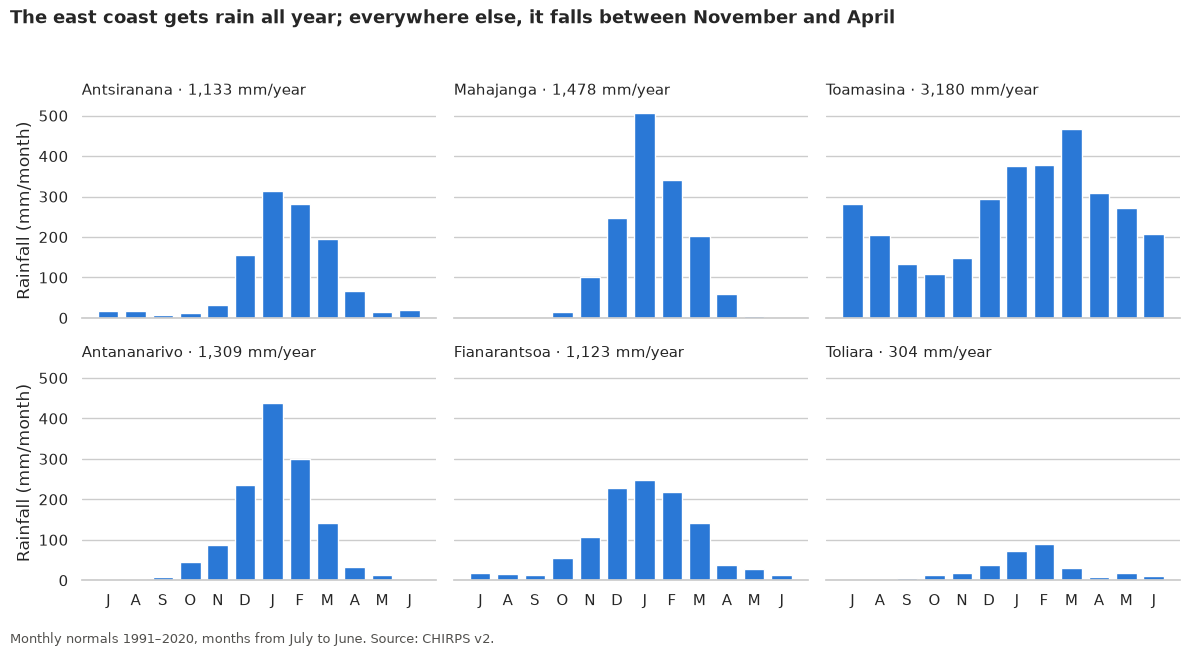

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True, sharey=True)

for ax, city in zip(axes.flat, CITY_ORDER):
    data = normals.loc[city].reindex(MONTH_ORDER)
    ax.bar(range(12), data["rain"], color=RAIN_COLOR, width=0.75)
    ax.set_title(f"{city.capitalize()} · {data['rain'].sum():,.0f} mm/year", loc="left", fontsize=11)
    ax.set_xticks(range(12), MONTH_LETTERS)
    sns.despine(ax=ax, left=True)

for ax in axes[:, 0]:
    ax.set_ylabel("Rainfall (mm/month)")

fig.suptitle("The east coast gets rain all year; everywhere else, it falls between November and April",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.005, "Monthly normals 1991–2020, months from July to June. Source: CHIRPS v2.",
         fontsize=9, color=NOTE_COLOR)
fig.tight_layout(rect=[0, 0.03, 1, 0.95])
fig.savefig(FIG_DIR / "01_rainfall_normals.png", dpi=200, bbox_inches="tight")
plt.show()

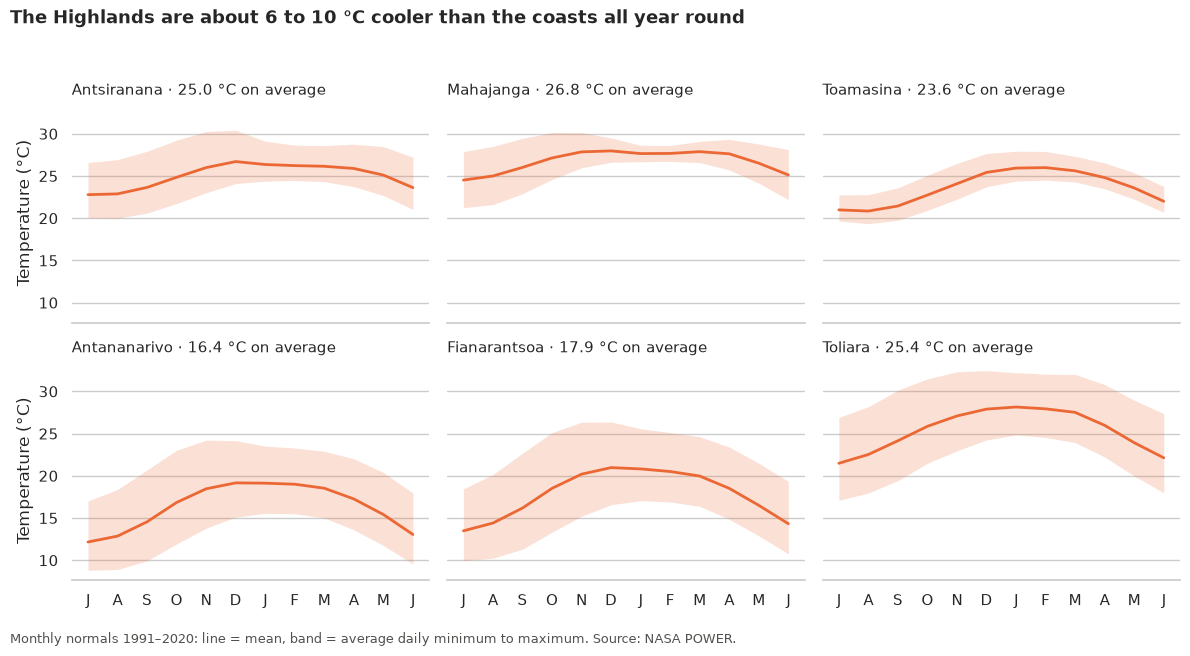

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True, sharey=True)

for ax, city in zip(axes.flat, CITY_ORDER):
    data = normals.loc[city].reindex(MONTH_ORDER)
    ax.fill_between(range(12), data["tmin"], data["tmax"], color=TEMP_COLOR, alpha=0.2, linewidth=0)
    ax.plot(range(12), data["tmean"], color=TEMP_COLOR, linewidth=2)
    ax.set_title(f"{city.capitalize()} · {data['tmean'].mean():.1f} °C on average", loc="left", fontsize=11)
    ax.set_xticks(range(12), MONTH_LETTERS)
    sns.despine(ax=ax, left=True)

for ax in axes[:, 0]:
    ax.set_ylabel("Temperature (°C)")

fig.suptitle("The Highlands are about 6 to 10 °C cooler than the coasts all year round",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.005, "Monthly normals 1991–2020: line = mean, band = average daily minimum to maximum. Source: NASA POWER.",
         fontsize=9, color=NOTE_COLOR)
fig.tight_layout(rect=[0, 0.03, 1, 0.95])
fig.savefig(FIG_DIR / "02_temperature_normals.png", dpi=200, bbox_inches="tight")
plt.show()

**Observations.** Rainfall seasonality differs sharply between regions. Toamasina, on the east coast, receives more than 100 mm even in its driest month, while every other city gets almost all its rain between November and April. Mahajanga has the most concentrated season (about 500 mm in January, almost nothing from May to October), so a late start of the rains matters most there; Toliara's rainy season is barely visible. Temperatures follow altitude: the Highlands are about 6 to 10 °C cooler than the coasts all year round, and they, like Toliara, have a wide gap between day and night (about 10 °C), whereas the ocean keeps Toamasina's daily range narrow (about 5 °C).

## 3. Trends since 1981
For each city, annual values are computed (mean temperatures, total rainfall), then their trend is measured with two methods:
- **Linear regression**: slope of the best-fit line.
- **Mann-Kendall test with Sen's slope**: the standard method in climatology, robust to exceptional years.

Slopes are given **per decade**. A trend is called significant when the Mann-Kendall p-value is below 0.05.

In [7]:
from scipy import stats
import pymannkendall as mk

annual = df.groupby(["city", "year"]).agg(
    tmean=("T2M", "mean"),
    tmax=("T2M_MAX", "mean"),
    tmin=("T2M_MIN", "mean"),
    rain=("rain_chirps", "sum"),
    tmean_era5=("tmean_era5", "mean"),
    tmax_era5=("tmax_era5", "mean"),
    tmin_era5=("tmin_era5", "mean"),
).reset_index()

annual.head()

,city,year,tmean,tmax,tmin,rain,tmean_era5,tmax_era5,tmin_era5
0,antananarivo,1981,16.090521,21.007288,12.270712,1141.374557,18.344932,23.846027,14.116438
1,antananarivo,1982,16.083205,20.727288,12.466548,1702.703484,18.206849,23.446027,14.255068
2,antananarivo,1983,16.217205,21.276740,12.306575,1565.845519,18.497808,24.132877,14.235890
3,antananarivo,1984,15.672869,20.542814,11.907104,1520.389920,17.830328,23.016393,13.832240
4,antananarivo,1985,15.534329,20.508137,11.697068,1549.905242,17.685205,23.014521,13.625753


In [8]:
VARIABLES = ["tmean", "tmax", "tmin", "rain", "tmean_era5", "tmax_era5", "tmin_era5"]

rows = []
for city in CITY_ORDER:
    sub = annual[annual["city"] == city].sort_values("year")
    for var in VARIABLES:
        lr = stats.linregress(sub["year"], sub[var])
        mkt = mk.original_test(sub[var])
        mkt_hr = mk.hamed_rao_modification_test(sub[var])
        rows.append({
            "city": city,
            "variable": var,
            "ols_per_decade": lr.slope * 10,
            "sen_per_decade": mkt.slope * 10,
            "mk_p": mkt.p,
            "mk_hr_p": mkt_hr.p,
            "significant": (mkt_hr.p if pd.notna(mkt_hr.p) else mkt.p) < 0.05,
        })

trends = pd.DataFrame(rows)
trends.round(3)

/home/nirinahelena/Documents/heather/heather/.venv/lib64/python3.14/site-packages/pymannkendall/pymannkendall.py:99: RuntimeWarning: invalid value encountered in sqrt
  z = (s - 1)/np.sqrt(var_s)
/home/nirinahelena/Documents/heather/heather/.venv/lib64/python3.14/site-packages/pymannkendall/pymannkendall.py:103: RuntimeWarning: invalid value encountered in sqrt
  z = (s + 1)/np.sqrt(var_s)


,city,variable,ols_per_decade,sen_per_decade,mk_p,mk_hr_p,significant
0,antsiranana,tmean,0.243,0.246,0.000,0.000,True
1,antsiranana,tmax,0.271,0.243,0.000,0.000,True
2,antsiranana,tmin,0.214,0.221,0.000,0.000,True
3,antsiranana,rain,-22.610,-10.563,0.618,0.618,False
4,antsiranana,tmean_era5,0.176,0.180,0.000,0.000,True
5,antsiranana,tmax_era5,0.187,0.173,0.000,0.000,True
6,antsiranana,tmin_era5,0.146,0.158,0.000,0.001,True
7,mahajanga,tmean,0.195,0.199,0.000,0.000,True
8,mahajanga,tmax,0.218,0.216,0.000,0.000,True
9,mahajanga,tmin,0.179,0.191,0.000,0.000,True


In [9]:
def label(row):
    """Sen slope per decade, with * when significant (p < 0.05)."""
    star = "*" if row["significant"] else ""
    return f"{row['sen_per_decade']:+.2f}{star}"

summary = (
    trends.assign(trend=trends.apply(label, axis=1))
    .pivot(index="city", columns="variable", values="trend")
    .loc[CITY_ORDER, ["tmean", "tmax", "tmin", "rain"]]
    .rename(columns={
        "tmean": "Mean temp (°C/decade)",
        "tmax": "Max temp (°C/decade)",
        "tmin": "Min temp (°C/decade)",
        "rain": "Rainfall (mm/decade)",
    })
)
summary

variable,Mean temp (°C/decade),Max temp (°C/decade),Min temp (°C/decade),Rainfall (mm/decade)
city,,,,
antsiranana,+0.25*,+0.24*,+0.22*,-10.56
mahajanga,+0.20*,+0.22*,+0.19*,-60.79*
toamasina,+0.22*,+0.25*,+0.20*,-45.99
antananarivo,+0.25*,+0.32*,+0.23*,-35.25
fianarantsoa,+0.45*,+0.67*,+0.29*,-28.99
toliara,+0.11*,+0.14*,+0.14*,-0.85


**Observations.** All six cities have warmed significantly since 1981, and both sources agree on it. The consensus is about +0.2 to +0.25 °C per decade, roughly +1 °C over 45 years. Daytime maximum temperatures rise faster than night-time minimums in both datasets, which is unusual compared with the global pattern. The two sources disagree on the size of the trend in two cities. In Fianarantsoa, NASA POWER (+0.45 °C/decade) diverges from Antananarivo after 2014 while ERA5 (+0.26 °C/decade) does not, so the NASA POWER value is most likely a model artefact. In Toliara, NASA POWER (+0.11) is far below ERA5 (+0.25). For these two cities, only the direction of the trend is certain, not its size. ERA5 is used as the main temperature source from here on.

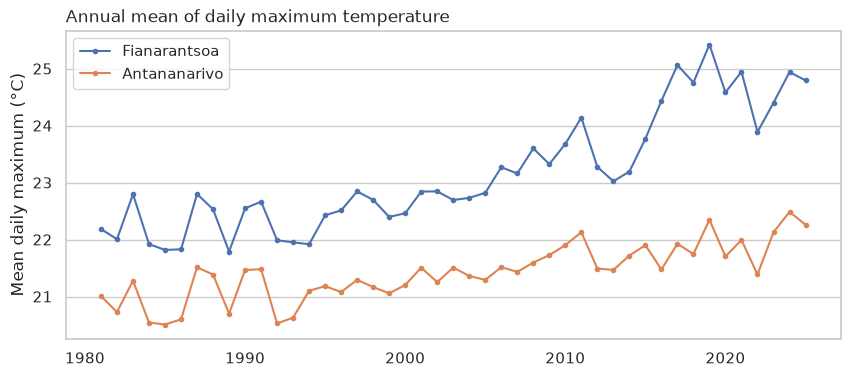

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
for city in ["fianarantsoa", "antananarivo"]:
    sub = annual[annual["city"] == city]
    ax.plot(sub["year"], sub["tmax"], marker="o", markersize=3, label=city.capitalize())
ax.set_ylabel("Mean daily maximum (°C)")
ax.set_title("Annual mean of daily maximum temperature", loc="left")
ax.legend()
plt.show()

**Observations.** All six cities have warmed significantly since 1981, and both sources agree on it. The consensus is about +0.2 to +0.25 °C per decade, roughly +1 °C over 45 years. Daytime maximum temperatures rise faster than night-time minimums in both datasets, which is unusual compared with the global pattern. The two sources disagree on the size of the trend in two cities. In Fianarantsoa, NASA POWER (+0.45 °C/decade) diverges from Antananarivo after 2014 while ERA5 (+0.26 °C/decade) does not, so the NASA POWER value is most likely a model artefact. In Toliara, NASA POWER (+0.11) is far below ERA5 (+0.25). For these two cities, only the direction of the trend is certain, not its size. ERA5 is used as the main temperature source from here on.

### Cross-check of temperature trends: NASA POWER vs ERA5
Sen's slope in °C per decade; * = significant with the Hamed-Rao corrected Mann-Kendall test (p < 0.05).

In [11]:
temp = trends[trends["variable"] != "rain"].copy()
temp["source"] = temp["variable"].str.endswith("_era5").map({True: "ERA5", False: "NASA POWER"})
temp["measure"] = temp["variable"].str.replace("_era5", "")
temp["trend"] = temp.apply(label, axis=1)

comparison = temp.pivot(index="city", columns=["measure", "source"], values="trend")
comparison.loc[CITY_ORDER, [(m, s) for m in ["tmean", "tmax", "tmin"] for s in ["NASA POWER", "ERA5"]]]

measure           tmean               tmax               tmin        
source       NASA POWER    ERA5 NASA POWER    ERA5 NASA POWER    ERA5
city                                                                 
antsiranana      +0.25*  +0.18*     +0.24*  +0.17*     +0.22*  +0.16*
mahajanga        +0.20*  +0.20*     +0.22*  +0.22*     +0.19*  +0.16*
toamasina        +0.22*  +0.22*     +0.25*  +0.27*     +0.20*  +0.19*
antananarivo     +0.25*  +0.26*     +0.32*  +0.37*     +0.23*  +0.23*
fianarantsoa     +0.45*  +0.26*     +0.67*  +0.40*     +0.29*  +0.23*
toliara          +0.11*  +0.25*     +0.14*  +0.37*     +0.14*  +0.22*

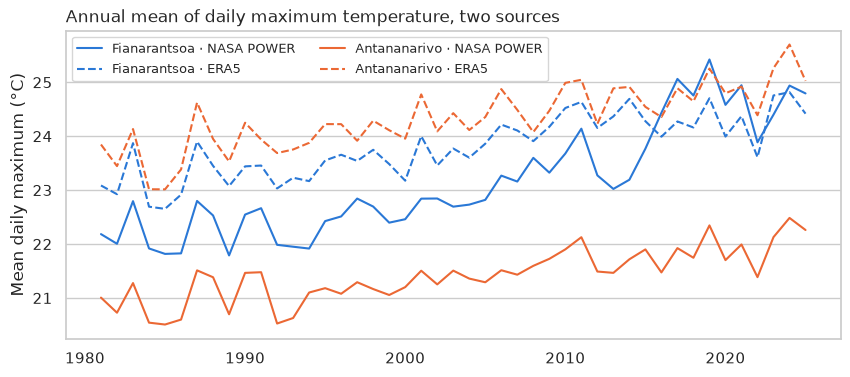

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
for city, color in [("fianarantsoa", "#2a78d6"), ("antananarivo", "#eb6834")]:
    sub = annual[annual["city"] == city]
    ax.plot(sub["year"], sub["tmax"], color=color, label=f"{city.capitalize()} · NASA POWER")
    ax.plot(sub["year"], sub["tmax_era5"], color=color, linestyle="--", label=f"{city.capitalize()} · ERA5")
ax.set_ylabel("Mean daily maximum (°C)")
ax.set_title("Annual mean of daily maximum temperature, two sources", loc="left")
ax.legend(ncols=2, fontsize=9)
plt.show()

## 4. Warming stripes
Each stripe is one year. Its colour shows the **anomaly**: the difference between that year's mean temperature and the city's 1991–2020 average (blue = cooler, red = warmer). Using anomalies puts cities with very different climates on the same scale. Source: ERA5.

In [13]:
ref_mean = annual[annual["year"].between(1991, 2020)].groupby("city")["tmean_era5"].mean()
annual["anomaly_era5"] = annual["tmean_era5"] - annual["city"].map(ref_mean)

stripes = annual.pivot(index="city", columns="year", values="anomaly_era5").loc[CITY_ORDER]
stripes.round(2).iloc[:, [0, 1, 2, -3, -2, -1]]

year,1981,1982,1983,2023,2024,2025
city,,,,,,
antsiranana,0.13,0.15,0.04,0.86,0.75,0.68
mahajanga,-0.34,-0.22,-0.26,0.68,0.84,0.45
toamasina,-0.22,-0.18,-0.15,0.72,0.54,0.45
antananarivo,-0.31,-0.45,-0.16,0.73,0.83,0.47
fianarantsoa,-0.46,-0.58,-0.06,0.66,0.62,0.54
toliara,-1.06,-0.90,0.02,-0.02,0.81,0.20


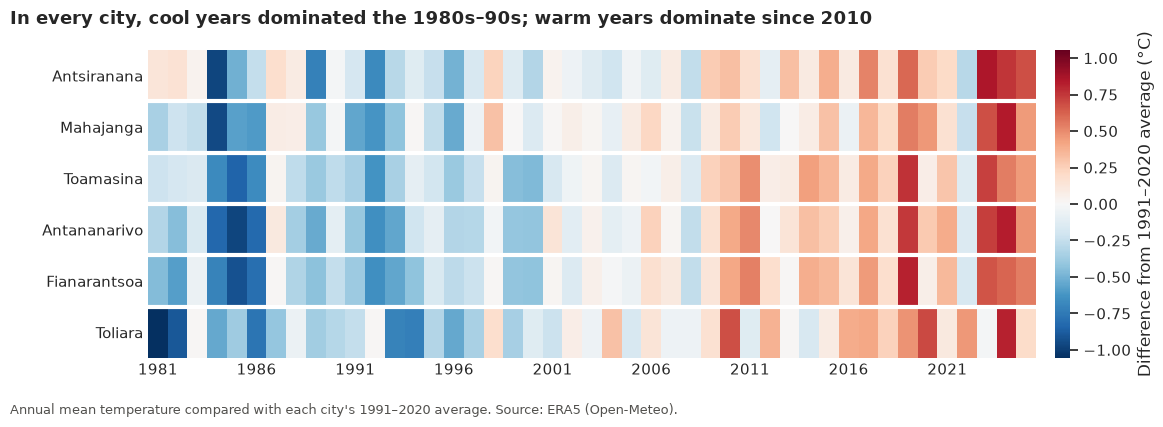

In [14]:
lim = stripes.abs().max().max()
years = stripes.columns

fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(stripes.values, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)

for y in range(1, len(CITY_ORDER)):
    ax.axhline(y - 0.5, color="white", linewidth=3)

ax.set_yticks(range(len(CITY_ORDER)), [c.capitalize() for c in CITY_ORDER])
ax.set_xticks(range(0, len(years), 5), years[::5])
ax.grid(False)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("Difference from 1991–2020 average (°C)")
cbar.outline.set_visible(False)

fig.suptitle("In every city, cool years dominated the 1980s–90s; warm years dominate since 2010",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.03, "Annual mean temperature compared with each city's 1991–2020 average. Source: ERA5 (Open-Meteo).",
         fontsize=9, color=NOTE_COLOR)
fig.savefig(FIG_DIR / "03_warming_stripes.png", dpi=200, bbox_inches="tight")
plt.show()

**Observations.** The shift is the same everywhere: cool years (blue) dominate the 1980s and 1990s, warm years (red) dominate since about 2010, and 2024 is the warmest year in most cities. The six cities also change colour together — 1984–85 is cool and 2019 and 2024 are warm from north to south — which points to large-scale drivers (such as El Niño or Indian Ocean temperatures) on top of the long-term warming. Toliara shows the strongest year-to-year swings.

## 5. Rain reliability: onset of the rainy season and false starts
**Onset** = first day from 1 September with at least 20 mm of rain over 3 days, not followed by a dry spell of 10 days or more (< 1 mm/day) within the next 30 days.
**False start** = a 20 mm / 3 days event that *is* followed by such a dry spell: the situation in which farmers sow too early and lose their seeds.
Seasons run from 1 September to 30 June (1981–82 to 2024–25, 44 seasons). Daily CHIRPS values are approximate, so onset dates are indicative; long-term changes are more robust.

In [15]:
ONSET_MM = 20          # rain needed over 3 days to count as a possible start
DRY_DAY_MM = 1         # a day with less than this is a dry day
DRY_SPELL_DAYS = 10    # a dry spell this long ruins the sowing
CHECK_DAYS = 30        # how long after the rains we check for a dry spell


def longest_run(mask: pd.Series) -> int:
    """Length of the longest run of consecutive True values."""
    if not mask.any():
        return 0
    runs = (mask != mask.shift()).cumsum()
    return int(mask.groupby(runs).sum().max())


def onset_and_false_starts(rain: pd.Series):
    """Onset date and number of false starts for one season of daily rainfall."""
    wet3 = rain.rolling(3).sum().shift(-2)      # rain on day d, d+1 and d+2
    dry = rain < DRY_DAY_MM
    false_starts = 0
    skip_until = None

    for day in wet3[wet3 >= ONSET_MM].index:
        if skip_until is not None and day <= skip_until:
            continue                            # same rainy event as the last false start
        start = day + pd.Timedelta(days=3)
        after = dry[start : start + pd.Timedelta(days=CHECK_DAYS - 1)]
        if longest_run(after) >= DRY_SPELL_DAYS:
            false_starts += 1
            next_dry = dry[day:][dry[day:]].index
            skip_until = next_dry[0] if len(next_dry) else day
        else:
            return day, false_starts
    return pd.NaT, false_starts

In [16]:
rows = []
for city in CITY_ORDER:
    city_rain = df[df["city"] == city].set_index("date")["rain_chirps"]
    for hy in range(1981, 2025):
        season = city_rain[f"{hy}-09-01" : f"{hy + 1}-06-30"]
        onset, n_false = onset_and_false_starts(season)
        rows.append({
            "city": city,
            "hydro_year": hy,
            "onset": onset,
            "onset_day": (onset - pd.Timestamp(f"{hy}-09-01")).days if pd.notna(onset) else float("nan"),
            "false_starts": n_false,
        })

seasons = pd.DataFrame(rows)
seasons.head(10)

,city,hydro_year,onset,onset_day,false_starts
0,antsiranana,1981,1981-12-03,93.0,6
1,antsiranana,1982,1982-11-29,89.0,1
2,antsiranana,1983,1983-12-08,98.0,0
3,antsiranana,1984,1984-12-14,104.0,3
4,antsiranana,1985,1985-12-31,121.0,3
5,antsiranana,1986,1986-11-24,84.0,0
6,antsiranana,1987,1988-01-09,130.0,4
7,antsiranana,1988,1988-12-10,100.0,0
8,antsiranana,1989,1989-12-09,99.0,0
9,antsiranana,1990,1990-12-25,115.0,6


In [17]:
def day_to_date(d):
    """Turn 'days after 1 September' into a readable date such as '28 Oct'."""
    return (pd.Timestamp("2001-09-01") + pd.Timedelta(days=d)).strftime("%d %b") if pd.notna(d) else "—"

season_summary = seasons.groupby("city").agg(
    median_onset_day=("onset_day", "median"),
    onset_spread_days=("onset_day", "std"),
    seasons_without_onset=("onset_day", lambda s: s.isna().sum()),
    mean_false_starts=("false_starts", "mean"),
).loc[CITY_ORDER]
season_summary["median_onset"] = season_summary["median_onset_day"].apply(day_to_date)
season_summary.round(1)

,median_onset_day,onset_spread_days,seasons_without_onset,mean_false_starts,median_onset
city,,,,,
antsiranana,113.0,17.0,1,3.4,23 Dec
mahajanga,81.0,14.5,0,1.7,21 Nov
toamasina,1.0,33.4,0,1.2,02 Sep
antananarivo,77.0,22.2,0,2.1,17 Nov
fianarantsoa,73.5,21.7,0,3.1,13 Nov
toliara,134.0,21.4,21,4.7,13 Jan


### Is the rainy season becoming less reliable?
Toamasina is excluded: it rains in every month, so the season has no meaningful start. Trends use Sen's slope against the actual years and Kendall's tau for significance, which handles seasons without an onset (Toliara). Variability is compared between the first and second halves of the period (1981–2002 vs 2003–2024).

In [18]:
SEASON_CITIES = [c for c in CITY_ORDER if c != "toamasina"]


def sen_trend(sub: pd.DataFrame, col: str) -> tuple[float, float]:
    """Sen's slope per decade and Kendall p-value, ignoring missing seasons."""
    sub = sub.dropna(subset=[col])
    slope = stats.theilslopes(sub[col], sub["hydro_year"]).slope * 10
    p = stats.kendalltau(sub["hydro_year"], sub[col]).pvalue
    return slope, p


rows = []
for city in SEASON_CITIES:
    sub = seasons[seasons["city"] == city]
    first = sub[sub["hydro_year"] <= 2002]
    second = sub[sub["hydro_year"] >= 2003]
    onset_slope, onset_p = sen_trend(sub, "onset_day")
    false_slope, false_p = sen_trend(sub, "false_starts")
    rows.append({
        "city": city,
        "onset_trend_days_per_decade": onset_slope,
        "onset_p": onset_p,
        "onset_spread_1981_2002": first["onset_day"].std(),
        "onset_spread_2003_2024": second["onset_day"].std(),
        "false_starts_trend_per_decade": false_slope,
        "false_starts_p": false_p,
        "false_starts_1981_2002": first["false_starts"].mean(),
        "false_starts_2003_2024": second["false_starts"].mean(),
        "no_onset_1981_2002": first["onset_day"].isna().sum(),
        "no_onset_2003_2024": second["onset_day"].isna().sum(),
    })

reliability = pd.DataFrame(rows).set_index("city")
reliability.round(2)

,onset_trend_days_per_decade,onset_p,onset_spread_1981_2002,onset_spread_2003_2024,false_starts_trend_per_decade,false_starts_p,false_starts_1981_2002,false_starts_2003_2024,no_onset_1981_2002,no_onset_2003_2024
city,,,,,,,,,,
antsiranana,3.24,0.13,17.09,17.29,-0.0,0.67,3.86,3.00,1,0
mahajanga,-0.00,0.90,15.75,13.33,-0.0,0.89,1.91,1.45,0,0
antananarivo,-1.02,0.78,25.60,18.70,-0.0,0.30,2.64,1.59,0,0
fianarantsoa,0.85,0.66,25.40,17.33,-0.0,0.82,3.50,2.77,0,0
toliara,5.77,0.15,18.37,23.81,-0.0,0.79,5.09,4.36,11,10


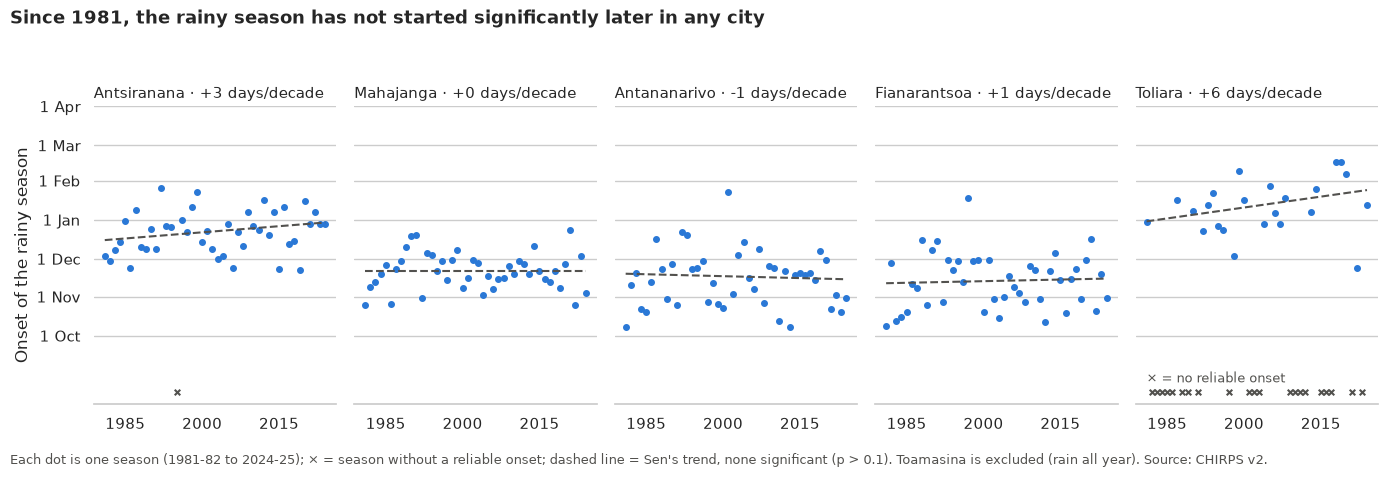

In [19]:
import numpy as np

# Days after 1 September -> readable dates for the y-axis
DATE_TICKS = {30: "1 Oct", 61: "1 Nov", 91: "1 Dec", 122: "1 Jan", 153: "1 Feb", 181: "1 Mar", 212: "1 Apr"}
NO_ONSET_Y = -15   # where seasons without an onset are marked

fig, axes = plt.subplots(1, len(SEASON_CITIES), figsize=(14, 4.5), sharey=True)

for ax, city in zip(axes, SEASON_CITIES):
    sub = seasons[seasons["city"] == city]
    ok = sub.dropna(subset=["onset_day"])
    missing = sub[sub["onset_day"].isna()]

    ax.scatter(ok["hydro_year"], ok["onset_day"], s=16, color=RAIN_COLOR)
    fit = stats.theilslopes(ok["onset_day"], ok["hydro_year"])
    xs = np.array([1981, 2024])
    ax.plot(xs, fit.intercept + fit.slope * xs, color=NOTE_COLOR, linestyle="--", linewidth=1.5)
    if len(missing):
        ax.scatter(missing["hydro_year"], [NO_ONSET_Y] * len(missing), marker="x", s=16, color=NOTE_COLOR)

    trend = round(reliability.loc[city, "onset_trend_days_per_decade"]) + 0
    ax.set_title(f"{city.capitalize()} · {trend:+.0f} days/decade", loc="left", fontsize=11)
    ax.set_xticks([1985, 2000, 2015])
    sns.despine(ax=ax, left=True)

axes[0].set_yticks(list(DATE_TICKS), list(DATE_TICKS.values()))
axes[0].set_ylabel("Onset of the rainy season")
axes[-1].annotate("× = no reliable onset", xy=(1981, NO_ONSET_Y + 8), fontsize=9, color=NOTE_COLOR)

fig.suptitle("Since 1981, the rainy season has not started significantly later in any city",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.03, "Each dot is one season (1981-82 to 2024-25); × = season without a reliable onset; dashed line = Sen's trend, "
         "none significant (p > 0.1). Toamasina is excluded (rain all year). Source: CHIRPS v2.", fontsize=9, color=NOTE_COLOR)
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(FIG_DIR / "04_rainy_season_onset.png", dpi=200, bbox_inches="tight")
plt.show()

**Observations.** The data do not show a rainy season that has become less reliable for farmers. In none of the five cities has the onset moved significantly since 1981, and false starts have slightly decreased everywhere (for example from 2.6 to 1.6 per season in Antananarivo). On the Highlands, the start date has even become more regular: its year-to-year spread fell from about 25 to 18 days. Toliara is the exception, but its risk is permanent rather than new. Half of its seasons (21 out of 44) never reach a reliable onset, it has the most false starts (4.7 per season), and when the rains do start, they start late (January to March). Its onset is drifting later and becoming more variable, but not significantly. In Mahajanga, annual rainfall has fallen significantly while the onset date has not changed, so the decline comes from less rain *during* the season, not a later start.

**Caution.** The onset rule comes from studies of wetter climates and is demanding for semi-arid Toliara; daily CHIRPS values are approximate, so dates are indicative to within a few days.

## 6. Drought: Standardized Precipitation Index (SPI)
The SPI compares rainfall accumulated over several months with what is normal for that city and that time of year (gamma distribution fitted on 1991–2020, then converted to a standard score). 0 = normal; ≤ -1 = moderate drought; ≤ -1.5 = severe drought. Because each city is compared with its own history, the SPI works for wet and arid climates alike.
- **Seasonal SPI-6** (rainfall from November to April): one value per rainy season.
- **SPI-3** in rainy-season months: number of drought months.

In [20]:
from scipy.stats import gamma, norm

RAINY_MONTHS = [11, 12, 1, 2, 3, 4]

monthly_rain = (
    df.groupby(["city", pd.Grouper(key="date", freq="MS")])["rain_chirps"].sum()
    .rename("rain").reset_index()
)


def spi(rain: pd.Series, dates: pd.Series, k: int) -> pd.Series:
    """SPI over k months for one city's monthly rainfall, fitted on 1991-2020."""
    totals = rain.rolling(k).sum()
    out = pd.Series(np.nan, index=rain.index)
    months = dates.dt.month
    in_ref = dates.dt.year.between(1991, 2020)
    for m in range(1, 13):
        same_month = (months == m) & totals.notna()
        ref = totals[same_month & in_ref]
        q = (ref == 0).mean()                  # probability of no rain at all
        wet = ref[ref > 0]
        if len(wet) < 10:
            continue                           # too few rainy cases to fit a distribution
        a, loc, scale = gamma.fit(wet, floc=0)
        prob = q + (1 - q) * gamma.cdf(totals[same_month], a, loc=loc, scale=scale)
        out[same_month] = norm.ppf(np.clip(prob, 0.001, 0.999))
    return out


parts = []
for city in CITY_ORDER:
    sub = monthly_rain[monthly_rain["city"] == city].sort_values("date").copy()
    sub["spi3"] = spi(sub["rain"], sub["date"], 3)
    sub["spi6"] = spi(sub["rain"], sub["date"], 6)
    parts.append(sub)

spi_df = pd.concat(parts, ignore_index=True)
spi_df["hydro_year"] = spi_df["date"].dt.year.where(spi_df["date"].dt.month >= 7, spi_df["date"].dt.year - 1)
spi_df.tail()

,city,date,rain,spi3,spi6,hydro_year
3235,toliara,2025-08-01,6.547556,1.323054,1.013862,2025
3236,toliara,2025-09-01,0.000000,0.687745,-0.168907,2025
3237,toliara,2025-10-01,7.841327,-0.355834,-0.009776,2025
3238,toliara,2025-11-01,15.189544,-0.697583,-0.224953,2025
3239,toliara,2025-12-01,33.028864,-0.388371,-0.271492,2025


In [21]:
check = spi_df[spi_df["date"].dt.year.between(1991, 2020)]
check.groupby("city")[["spi3", "spi6"]].agg(["mean", "std"]).round(2)

spi3       spi6     
              mean   std mean  std
city                              
antananarivo  0.01  0.99  0.0  1.0
antsiranana  -0.00  1.00 -0.0  1.0
fianarantsoa -0.00  1.00 -0.0  1.0
mahajanga     0.05  0.97  0.0  1.0
toamasina     0.00  1.00 -0.0  1.0
toliara       0.01  0.99 -0.0  1.0

In [22]:
season_spi = spi_df[spi_df["date"].dt.month == 4].copy()
season_spi["season"] = season_spi["date"].dt.year - 1        # April 2021 closes the 2020-21 season

rows = []
for city in CITY_ORDER:
    s = season_spi[season_spi["city"] == city].dropna(subset=["spi6"]).sort_values("season")
    m = spi_df[(spi_df["city"] == city) & spi_df["date"].dt.month.isin(RAINY_MONTHS)]
    first, second = s[s["season"] <= 2002], s[s["season"] >= 2003]
    worst = int(s.loc[s["spi6"].idxmin(), "season"])
    t = mk.original_test(s["spi6"])
    rows.append({
        "city": city,
        "spi6_trend_per_decade": t.slope * 10,
        "p": t.p,
        "dry_seasons_1981_2002": (first["spi6"] <= -1).sum(),
        "dry_seasons_2003_2024": (second["spi6"] <= -1).sum(),
        "severe_1981_2002": (first["spi6"] <= -1.5).sum(),
        "severe_2003_2024": (second["spi6"] <= -1.5).sum(),
        "drought_months_1981_2002": (m.loc[m["hydro_year"].between(1981, 2002), "spi3"] <= -1).sum(),
        "drought_months_2003_2024": (m.loc[m["hydro_year"].between(2003, 2024), "spi3"] <= -1).sum(),
        "worst_season": f"{worst}-{str(worst + 1)[-2:]}",
        "worst_spi6": s["spi6"].min(),
    })

drought = pd.DataFrame(rows).set_index("city")
drought.round(2)

,spi6_trend_per_decade,p,dry_seasons_1981_2002,dry_seasons_2003_2024,severe_1981_2002,severe_2003_2024,drought_months_1981_2002,drought_months_2003_2024,worst_season,worst_spi6
city,,,,,,,,,,
antsiranana,-0.11,0.47,3,6,1,1,15,27,2024-25,-2.26
mahajanga,-0.28,0.06,2,7,0,6,19,32,2012-13,-2.69
toamasina,-0.35,0.01,1,6,1,1,15,18,1998-99,-2.71
antananarivo,-0.13,0.41,3,4,1,1,19,16,2016-17,-2.58
fianarantsoa,-0.19,0.14,3,1,2,0,18,19,1990-91,-2.45
toliara,-0.02,0.88,2,3,1,1,16,23,1991-92,-2.17


In [23]:
season_spi[(season_spi["city"] == "toliara") & season_spi["season"].between(2017, 2022)][["season", "spi6"]].round(2)

,season,spi6
3147,2017,-1.20
3159,2018,-0.34
3171,2019,-0.95
3183,2020,0.79
3195,2021,-1.17
3207,2022,1.51


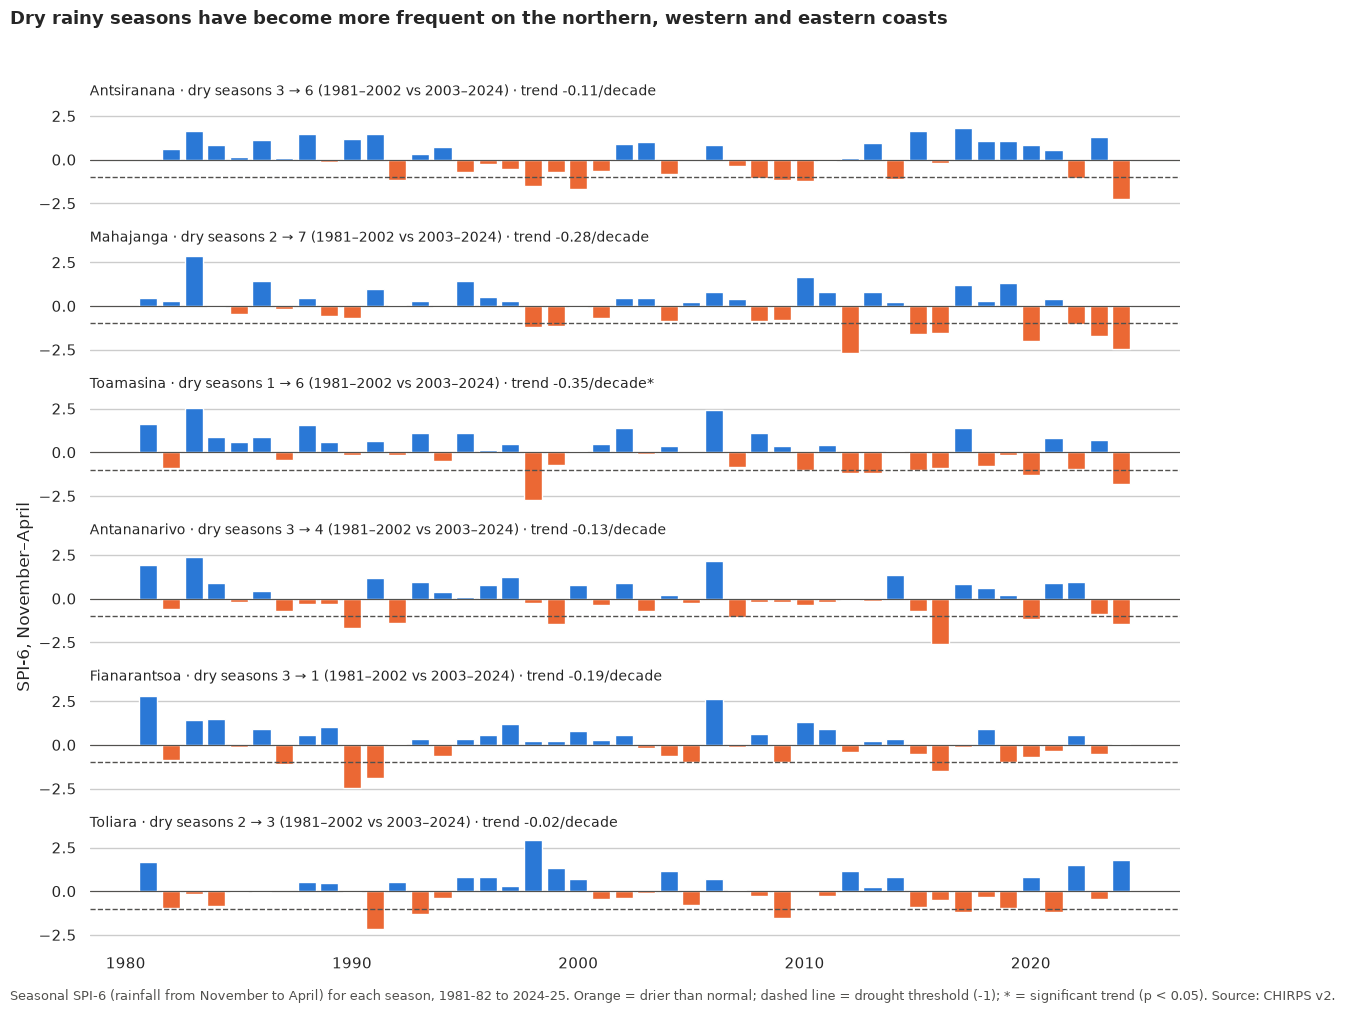

In [24]:
DRY_COLOR, WET_COLOR = "#eb6834", "#2a78d6"

fig, axes = plt.subplots(len(CITY_ORDER), 1, figsize=(12, 10), sharex=True, sharey=True)

for ax, city in zip(axes, CITY_ORDER):
    s = season_spi[season_spi["city"] == city].dropna(subset=["spi6"])
    ax.bar(s["season"], s["spi6"], color=np.where(s["spi6"] < 0, DRY_COLOR, WET_COLOR), width=0.8)
    ax.axhline(0, color=NOTE_COLOR, linewidth=0.8)
    ax.axhline(-1, color=NOTE_COLOR, linestyle="--", linewidth=1)
    row = drought.loc[city]
    star = "*" if row["p"] < 0.05 else ""
    ax.set_title(f"{city.capitalize()} · dry seasons {row['dry_seasons_1981_2002']} → {row['dry_seasons_2003_2024']} "
                 f"(1981–2002 vs 2003–2024) · trend {row['spi6_trend_per_decade']:+.2f}/decade{star}",
                 loc="left", fontsize=10)
    sns.despine(ax=ax, left=True, bottom=True)

axes[len(axes) // 2].set_ylabel("SPI-6, November–April")
fig.suptitle("Dry rainy seasons have become more frequent on the northern, western and eastern coasts",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.01, "Seasonal SPI-6 (rainfall from November to April) for each season, 1981-82 to 2024-25. Orange = drier than normal; "
         "dashed line = drought threshold (-1); * = significant trend (p < 0.05). Source: CHIRPS v2.",
         fontsize=9, color=NOTE_COLOR)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(FIG_DIR / "05_drought_spi.png", dpi=200, bbox_inches="tight")
plt.show()

**Observations.** Rainy seasons have become drier on the northern, western and eastern coasts, but not on the Highlands or in the South. Mahajanga shows the clearest change: dry seasons (SPI-6 ≤ -1) rose from 2 in 1981–2002 to 7 in 2003–2024, severe ones (≤ -1.5) from 0 to 6, and drought months from 19 to 32 — consistent with its significant decline in annual rainfall. Toamasina's rainy season is drying significantly (-0.35 per decade, p = 0.01) even though its annual total has no significant trend, and Antsiranana's driest season on record is the most recent one (2024–25). Antananarivo, Fianarantsoa and Toliara show no trend. All six trends point towards drier conditions, which makes the coastal signal more credible than any single p-value.

**Caution.** The severe 2020–21 drought of Madagascar's far south (Androy, Anosy) does not appear in Toliara, where that season was wetter than normal (SPI-6 = +0.79): drought can be very local, and six cities cannot represent the whole island. With six cities tested, one p-value below 0.05 could occur by chance; the consistency across cities and indicators is what supports the conclusion.

## 7. Dangerous heat: heat index
The heat index is the temperature the human body feels when heat and humidity combine. It is computed hour by hour from ERA5 temperature and humidity (NOAA formula), and the daily maximum is kept. NOAA thresholds:
- **≥ 32.2 °C (90 °F) — extreme caution**: heat cramps and heat exhaustion possible with prolonged exposure.
- **≥ 39.4 °C (103 °F) — danger**: heat exhaustion likely, heat stroke possible.

Values are for shade; full sunshine can raise the felt temperature further.

In [26]:
CAUTION_C, DANGER_C = 32.2, 39.4   # NOAA thresholds: 90 °F and 103 °F

heat_days = df.groupby(["city", "year"]).agg(
    caution_days=("hi_max_era5", lambda s: (s >= CAUTION_C).sum()),
    danger_days=("hi_max_era5", lambda s: (s >= DANGER_C).sum()),
).reset_index()

rows = []
for city in CITY_ORDER:
    sub = heat_days[heat_days["city"] == city].sort_values("year")
    early = sub[sub["year"].between(1981, 1990)]
    recent = sub[sub["year"].between(2016, 2025)]
    row = {"city": city}
    for col in ["caution_days", "danger_days"]:
        t = mk.original_test(sub[col])
        row[f"{col}_1981_1990"] = early[col].mean()
        row[f"{col}_2016_2025"] = recent[col].mean()
        row[f"{col}_trend_per_decade"] = t.slope * 10
        row[f"{col}_p"] = t.p
    rows.append(row)

heat_trends = pd.DataFrame(rows).set_index("city")
heat_trends.round(1)

,caution_days_1981_1990,caution_days_2016_2025,caution_days_trend_per_decade,caution_days_p,danger_days_1981_1990,danger_days_2016_2025,danger_days_trend_per_decade,danger_days_p
city,,,,,,,,
antsiranana,174.6,202.5,11.6,0.0,0.2,1.7,0.0,0.0
mahajanga,247.1,286.3,11.4,0.0,19.0,63.7,11.7,0.0
toamasina,107.9,149.4,13.3,0.0,4.5,17.3,3.3,0.0
antananarivo,0.0,0.3,0.0,0.0,0.0,0.0,0.0,1.0
fianarantsoa,0.0,0.9,0.0,0.0,0.0,0.0,0.0,1.0
toliara,150.0,181.8,9.9,0.0,7.8,25.2,4.2,0.0


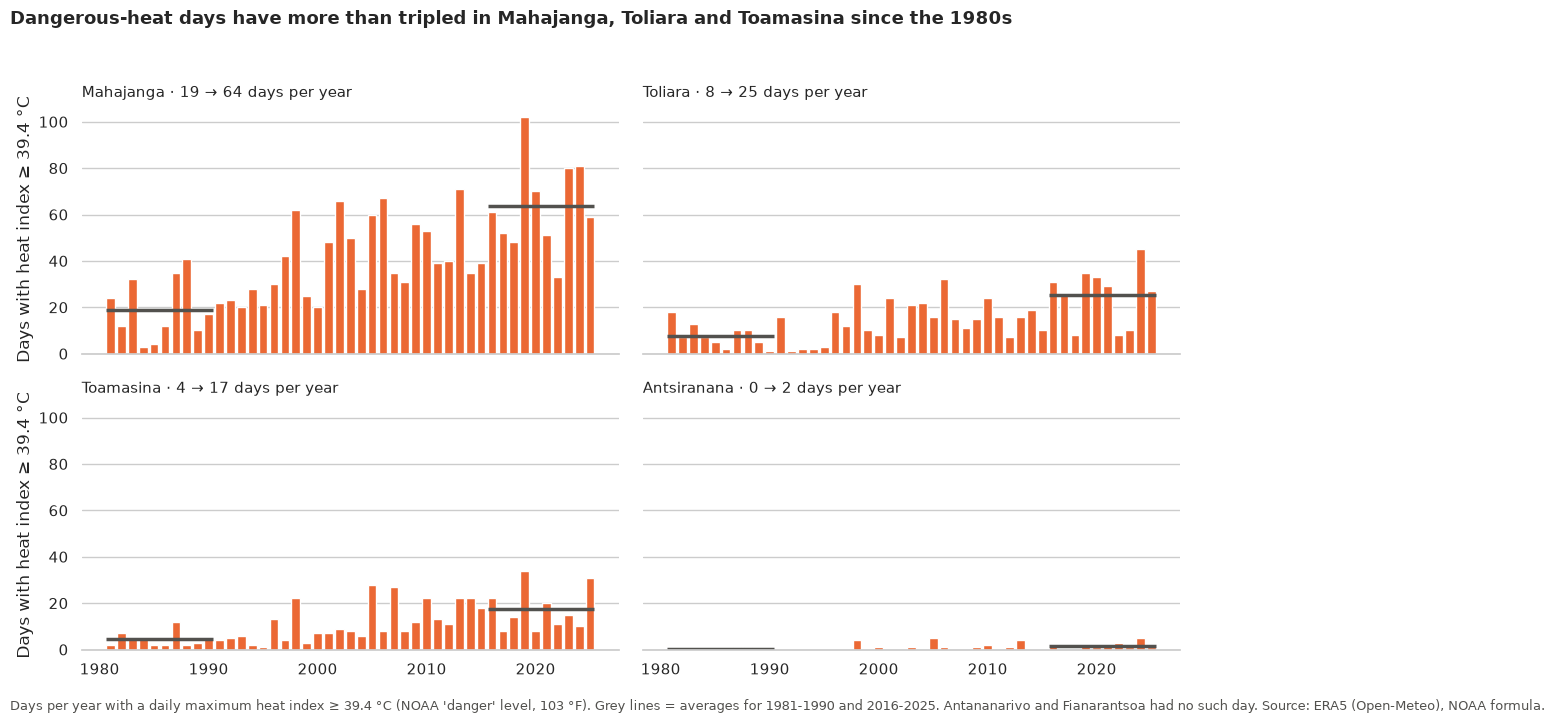

In [27]:
HEAT_CITIES = ["mahajanga", "toliara", "toamasina", "antsiranana"]

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)

for ax, city in zip(axes.flat, HEAT_CITIES):
    sub = heat_days[heat_days["city"] == city]
    row = heat_trends.loc[city]
    ax.bar(sub["year"], sub["danger_days"], color=TEMP_COLOR, width=0.8)
    for (y0, y1), col in [((1981, 1990), "danger_days_1981_1990"), ((2016, 2025), "danger_days_2016_2025")]:
        ax.hlines(row[col], y0 - 0.4, y1 + 0.4, color=NOTE_COLOR, linewidth=2.5)
    ax.set_title(f"{city.capitalize()} · {row['danger_days_1981_1990']:.0f} → "
                 f"{row['danger_days_2016_2025']:.0f} days per year", loc="left", fontsize=11)
    sns.despine(ax=ax, left=True)

for ax in axes[:, 0]:
    ax.set_ylabel("Days with heat index ≥ 39.4 °C")

fig.suptitle("Dangerous-heat days have more than tripled in Mahajanga, Toliara and Toamasina since the 1980s",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.02, "Days per year with a daily maximum heat index ≥ 39.4 °C (NOAA 'danger' level, 103 °F). Grey lines = averages "
         "for 1981-1990 and 2016-2025. Antananarivo and Fianarantsoa had no such day. Source: ERA5 (Open-Meteo), NOAA formula.",
         fontsize=9, color=NOTE_COLOR)
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(FIG_DIR / "06_dangerous_heat_days.png", dpi=200, bbox_inches="tight")
plt.show()

**Observations.** Dangerous heat is the fastest-growing risk in this study. Days with a heat index of at least 39.4 °C (NOAA "danger" level) have more than tripled on three coasts between 1981–1990 and 2016–2025: from 19 to 64 days per year in Mahajanga (about two months), from 8 to 25 in Toliara and from 4.5 to 17 in Toamasina. All three trends are significant (p < 0.001), and the rise is gradual rather than a sudden jump. In Mahajanga, the "extreme caution" level (≥ 32.2 °C) is now reached on 286 days per year — nearly 8 days out of 10. Such a large increase from a warming of only about 1 °C is a threshold effect: many days were just below the danger level, and a small shift in the average pushes them over it. The Highlands remain protected by altitude: Antananarivo and Fianarantsoa had no danger day at all.

**Caution.** The heat index is computed for shade and light wind; in full sunshine, outdoor workers feel even higher values. ERA5 grid cells (about 25 km) smooth out urban heat, which can make cities hotter still.

## 8. Comparison between regions
One row per city, bringing together the three risks measured above: dangerous heat, drought and rain reliability, plus the background warming.

In [28]:
warming = trends[trends["variable"] == "tmean_era5"].set_index("city")["sen_per_decade"]


def before_after(table: pd.DataFrame, city: str, before: str, after: str) -> str:
    """Format two values as 'before → after'."""
    return f"{table.loc[city, before]:.0f} → {table.loc[city, after]:.0f}"


rows = []
for city in CITY_ORDER:
    has_season = city in reliability.index
    rows.append({
        "city": city.capitalize(),
        "Warming (°C/decade, ERA5)": f"{warming[city]:+.2f}",
        "Danger-heat days/year (1981-90 → 2016-25)": before_after(heat_trends, city, "danger_days_1981_1990", "danger_days_2016_2025"),
        "Dry rainy seasons (1981-2002 → 2003-24)": before_after(drought, city, "dry_seasons_1981_2002", "dry_seasons_2003_2024"),
        "Seasons without reliable onset (of 44)": (
            f"{reliability.loc[city, 'no_onset_1981_2002'] + reliability.loc[city, 'no_onset_2003_2024']:.0f}"
            if has_season else "rain all year"
        ),
        "False starts per season (2003-24)": (
            f"{reliability.loc[city, 'false_starts_2003_2024']:.1f}" if has_season else "—"
        ),
    })

synthesis = pd.DataFrame(rows).set_index("city")
synthesis

,"Warming (°C/decade, ERA5)",Danger-heat days/year (1981-90 → 2016-25),Dry rainy seasons (1981-2002 → 2003-24),Seasons without reliable onset (of 44),False starts per season (2003-24)
city,,,,,
Antsiranana,+0.18,0 → 2,3 → 6,1,3.0
Mahajanga,+0.20,19 → 64,2 → 7,0,1.5
Toamasina,+0.22,4 → 17,1 → 6,rain all year,—
Antananarivo,+0.26,0 → 0,3 → 4,0,1.6
Fianarantsoa,+0.26,0 → 0,3 → 1,0,2.8
Toliara,+0.25,8 → 25,2 → 3,21,4.4


## 9. Conclusion

**Main question — Is Madagascar's climate becoming harder to live with?** Yes, but not in the same way everywhere. All six cities have warmed by about +0.2 to +0.26 °C per decade (about +1 °C since 1981, confirmed by two independent sources). This warming is almost uniform; what differs is how it turns into risk for people.

1. **Rain reliability (food).** No city shows a significantly later start of the rainy season, and false starts have slightly decreased. The problem is permanent rather than new: in Toliara, half of the seasons (21 out of 44) never reach a reliable onset, with 4.4 false starts per season.
2. **Drought (water).** Rainy seasons have become drier on the northern, western and eastern coasts. Dry seasons rose from 2 to 7 in Mahajanga, from 1 to 6 in Toamasina and from 3 to 6 in Antsiranana between 1981–2002 and 2003–2024. The Highlands and Toliara show no trend.
3. **Dangerous heat (health).** This is the fastest-growing risk. Days above the NOAA danger level more than tripled on three coasts between the 1980s and the last ten years: Mahajanga 19 → 64, Toliara 8 → 25, Toamasina 4 → 17 days per year. A warming of only about 1 °C is enough, because many days were just below the threshold.
4. **Inequality between regions.** The most exposed regions are not the same for every risk. Heat and drought grow on the coasts, while rain unreliability is a long-standing problem of the South. **Mahajanga is the hotspot**: it is the only city where two risks are rising together. The Highlands warm as fast as the coasts, but their altitude keeps them out of dangerous heat and they show no drying.

**Main limitations.** The data are gridded estimates (CHIRPS for rainfall, ERA5 for temperature and humidity), not station records; six cities cannot represent the whole island, as the 2020–21 drought of the far south showed; and this study measures climate hazards, not their impacts on harvests or health.